# Tissue niches, and how errors propagate across the four levels (§5.4–5.5)

Level 4: do we recover the same higher-order ecosystem? Reference niches are derived from the expert cells through
the fixed phenotyping and neighborhood pipeline — the cellular-neighborhood method of Schürch et al. (2020): for every
cell a window of its 10 nearest cells summarized as a lineage-frequency vector, windows clustered with $k$-means
($K{=}4$, the ceiling of a three-lineage composition space), each cell inheriting its window's cluster — giving four
niches: immune-infiltrated, epithelial core, interface, stromal. Each method's cells are assigned through *their own*
graphs and phenotypes, so every upstream error propagates into these maps, and the notebook closes with the paper's
central analysis: the four levels linked, asking whether segmentation accuracy predicts downstream reliability.

Needs notebooks 02–04 (`benchmark_region.csv`, `cells_*.csv`, `phenotype_summary.csv`, `neighborhood_summary.csv`).

In [1]:
# pick up edits to src/ without restarting the kernel
%load_ext autoreload
%autoreload 2
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from mxdata import DEFAULT_DATASET, load_config, load_regions, ingest, apply_qc_policy
from mxdata.data import LiveSource
from mxseg.evaluate import split_regions_of, read_prediction

# ---- edit here ---------------------------------------------------------------------------------------------------------
METHODS_ALL = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "kodiakb_frozen", "dinov3b_frozen", "cellpose_ft",
               "cellpose", "cpdino", "instanseg", "sam3", "sam3_text", "sam2"]
SHOW_METHODS = ["cellpose", "cellpose_ft", "sam3", "dinov3b_frozen", "unet_flows", "kodiakb_flows"]
SEED = 0                                        # the seed drawn in every figure; every table pools the seeds (mean ± std)
TEST_SLIDE = "SLIDE-0236"                       # the paper's Slide 2: every §5 analysis runs on it; the other held-out slide (SLIDE-0233,
                                                # Slide 3) is scored in notebook 02's Slide-3 table from the stored per-region results
# METHODS_ALL: the paper's order (ViT-B rows, 10-epoch budget, 3 seeds); a method enters once its test-slide predictions exist.
# SHOW_METHODS: the image figures.
# ------------------------------------------------------------------------------------------------------------------------

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ANALYSIS = REPO / "outputs" / "analysis"
ANALYSIS.mkdir(parents=True, exist_ok=True)
PRED = REPO / "outputs" / "region" / "test"        # mxseg eval -b configs/baselines/<method>.yaml --split test --unit region --store-predictions
cfg = load_config(REPO / "configs" / "dataset.yaml")

LABEL = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B/16", "dinov3b_flows": "DINOv3 B/16", "kodiakb_frozen": "KODIAK B/16, frozen",
         "dinov3b_frozen": "DINOv3 B/16, frozen", "cellpose_ft": "Cellpose, adapted", "cellpose": "Cellpose-SAM, zero-shot",
         "cpdino": "Cellpose (DINOv3), zero-shot", "instanseg": "InstanSeg", "sam3": "SAM 3, exemplar", "sam3_text": "SAM 3, text",
         "sam2": "SAM 2.1, prototype",
         "kodiak_flows": "KODIAK S/16", "dinov3_flows": "DINOv3 S/16", "dinov3_frozen": "DINOv3 S/16, frozen", "kodiak_frozen": "KODIAK S/16, frozen"}
SHORT = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B", "dinov3b_flows": "DINOv3 B", "kodiakb_frozen": "KODIAK B frozen",
         "dinov3b_frozen": "DINOv3 B frozen", "cellpose_ft": "Cellpose adapted", "cellpose": "Cellpose-SAM 0-shot", "cpdino": "Cellpose-DINO 0-shot",
         "instanseg": "InstanSeg", "sam3": "SAM 3 exemplar", "sam3_text": "SAM 3 text", "sam2": "SAM 2.1",
         "kodiak_flows": "KODIAK S", "dinov3_flows": "DINOv3 S", "dinov3_frozen": "DINOv3 S frozen", "kodiak_frozen": "KODIAK S frozen"}
MCOLOR = {"unet_flows": "#2A78D6", "kodiakb_flows": "#7E1F2E", "dinov3b_flows": "#6E5314", "kodiakb_frozen": "#DF959E", "dinov3b_frozen": "#D3BF8C",
          "cellpose_ft": "#EB6834", "cellpose": "#8A8A8A", "cpdino": "#5A5A5A", "instanseg": "#3C9D9B",
          "sam3": "#1BAF7A", "sam3_text": "#E87BA4", "sam2": "#9A86E0",
          "kodiak_flows": "#C43E4E", "dinov3_flows": "#B08A2E", "dinov3_frozen": "#D3BF8C", "kodiak_frozen": "#DF959E"}   # the paper's swatches; frozen = tints
INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
PHENO_COLOR = {"Epithelial": "#2A78D6", "Immune": "#C43E4E", "Other": "#AEB2B8"}
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def panel(ax, letter, dx=-0.04, dy=1.04):
    """Nature-style bold panel letter, outside the axes' top-left corner."""
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    """A short label inside an image panel (region, method) — never a sentence."""
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def xgrid(ax):
    ax.grid(axis="x", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def barh_clean(ax):
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

def hex2rgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

def short(key):
    return key.split("_")[-1]

def norm01(img, lo=1, hi=99):
    a, b = np.percentile(img, (lo, hi))
    return np.clip((img - a) / max(b - a, 1e-6), 0, 1)

per_slide = split_regions_of(DEFAULT_DATASET, "test", cfg.slides)          # the protocol: held-out test slides, every region reviewed
assert TEST_SLIDE in per_slide, f"{TEST_SLIDE} is not a test slide of the split: {list(per_slide)}"
OTHER_TEST = [s for s in per_slide if s != TEST_SLIDE]                     # also held out (Slide 3): never pooled with TEST_SLIDE here
paths, mx, _ = ingest(TEST_SLIDE, None)
ids = sorted(per_slide[TEST_SLIDE])
regions = {r.region_id: r for r in load_regions(paths, ids, cfg.min_area_px)}
src = LiveSource(mx, list(regions.values()), cfg.markers, cfg.level)
TEST = {}                                          # key -> DAPI, labels (expert-flagged nuclei zeroed) and their ignore mask
for key in src.keys:
    rs = src.load(key)
    labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong")
    r = regions[int(key.split("_R")[-1])]
    TEST[key] = dict(dapi=rs.image[0], labels=labels, ignore=ignore, region=r, has_qc=bool(r.has_qc))
PX_UM = float(mx.pixel_size_um or 0.325)

def runs_of(m):
    """The stored, complete runs of a method (every test region predicted): <method>_s<seed> for trained rows, the bare name for zero-shot rows."""
    names = sorted(d.name for d in PRED.glob(f"{m}_s[0-9]*") if d.is_dir()) or ([m] if (PRED / m).is_dir() else [])
    return [r for r in names if all((PRED / r / f"{k}.npz").is_file() for k in TEST)]
RUNS = {m: runs_of(m) for m in METHODS_ALL if runs_of(m)}
METHODS = list(RUNS)
RUN = {m: next((r for r in RUNS[m] if r.endswith(f"_s{SEED}")), RUNS[m][0]) for m in METHODS}   # the run drawn in the figures
if not METHODS:
    raise FileNotFoundError(f"no complete test-slide predictions under {PRED.relative_to(REPO)} — scripts/finetune_all.sh evaluates every run:  "
                            "mxseg eval -b configs/baselines/<method>.yaml --split test --unit region")
if len(METHODS) < len(METHODS_ALL):
    print("not evaluated yet, skipped:", ", ".join(LABEL[m] for m in METHODS_ALL if m not in METHODS))
SHOW = [m for m in SHOW_METHODS if m in METHODS]

def pred_of(run, key):
    """A stored instance map: ``run`` is a run name (<method>_s<seed>, or the bare name of a zero-shot row) or a method (its drawn run)."""
    return read_prediction(PRED / RUN.get(run, run) / f"{key}.npz")

def tag(key):
    return short(key) + ("*" if TEST[key]["has_qc"] else "")

def scalebar(ax, npx, um=50, color="white"):
    L = um / PX_UM
    x1, y = npx * 0.96, npx * 0.94
    ax.plot([x1 - L, x1], [y, y], color=color, lw=2.2, solid_capstyle="butt")
    ax.text(x1 - L / 2, y - npx * 0.025, f"{um} µm", color=color, ha="center", va="bottom", fontsize=7)

print(f"test slide {TEST_SLIDE}: {len(TEST)} regions ({', '.join(tag(k) for k in TEST)}; * = reviewed) | methods (seeds): "
      + ", ".join(f"{LABEL[m]} ({len(RUNS[m])})" for m in METHODS) + f" | figures draw seed {SEED}"
      + (f" | also held out, analysed separately: {', '.join(OTHER_TEST)}" if OTHER_TEST else ""))

/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})


test slide SLIDE-0236: 6 regions (R01*, R02*, R03*, R04*, R05*, R06*; * = reviewed) | methods (seeds): U-Net (3), KODIAK B/16 (3), DINOv3 B/16 (3), KODIAK B/16, frozen (3), DINOv3 B/16, frozen (3), Cellpose, adapted (3), Cellpose-SAM, zero-shot (1), Cellpose (DINOv3), zero-shot (1), InstanSeg (1), SAM 3, exemplar (1), SAM 3, text (1), SAM 2.1, prototype (1) | figures draw seed 0 | also held out, analysed separately: SLIDE-0233


In [2]:
from scipy.spatial import cKDTree
from sklearn.cluster import MiniBatchKMeans

CLASSES = ["Epithelial", "Immune", "Other"]
W_CN, NCN = 10, 4                                                              # Schürch window (center + 9 nearest), four CNs
NICHE_COLOR = {"Immune-infiltrated": "#C43E4E", "Epithelial core": "#2A78D6", "Interface": "#9A86E0", "Stromal / other": "#B9BDC4"}
if not (ANALYSIS / "cells_expert.csv").is_file():
    raise FileNotFoundError("run notebooks 02-04 first — no cells_expert.csv")
expert = pd.read_csv(ANALYSIS / "cells_expert.csv")
cells = {m: pd.read_csv(ANALYSIS / f"cells_{m}.csv") for m in METHODS if (ANALYSIS / f"cells_{m}.csv").is_file()}
METHODS = [m for m in METHODS if m in cells]
etab = expert.rename(columns={"id": "gt_id"})[["region", "gt_id", "cy", "cx"]]
for m in METHODS:
    cells[m] = cells[m].merge(etab, on=["region", "gt_id"], suffixes=("", "_e"))

def windows(cy, cx, pheno):
    """Schürch windows: frequency of each lineage among the W_CN nearest cells, the center included."""
    idx = {c: i for i, c in enumerate(CLASSES)}
    pts = np.column_stack([cy, cx])
    _, nn = cKDTree(pts).query(pts, k=min(W_CN, len(pts)))
    ph = np.array([idx[p] for p in pheno])
    comp = np.zeros((len(pts), len(CLASSES)))
    for i, row in enumerate(nn):
        for j in np.atleast_1d(row):
            comp[i, ph[j]] += 1
    return comp / np.maximum(comp.sum(1, keepdims=True), 1)

ecomp, frames = [], []
for key in TEST:
    e = expert[expert.region == key].reset_index(drop=True)
    ecomp.append(windows(e.cy.values, e.cx.values, list(e.pheno)))
    frames.append(e)
km = MiniBatchKMeans(NCN, n_init=10, random_state=0).fit(np.vstack(ecomp))
# name the four niches by rank, so every name is used exactly once whatever the composition: the most immune window type
# is immune-infiltrated; of the rest the most epithelial is the epithelial core; of the remaining two the more epithelial
# is the interface and the other stromal / other
cc_ = km.cluster_centers_; NAME = {}
left_ = list(range(NCN))
imm = max(left_, key=lambda c: cc_[c, CLASSES.index("Immune")]); NAME[imm] = "Immune-infiltrated"; left_.remove(imm)
core = max(left_, key=lambda c: cc_[c, CLASSES.index("Epithelial")]); NAME[core] = "Epithelial core"; left_.remove(core)
inter = max(left_, key=lambda c: cc_[c, CLASSES.index("Epithelial")]); NAME[inter] = "Interface"; left_.remove(inter)
NAME[left_[0]] = "Stromal / other"
expert = pd.concat(frames, ignore_index=True)
expert["niche"] = [NAME[c] for c in km.labels_]
centers = pd.DataFrame(km.cluster_centers_, columns=CLASSES, index=[NAME[i] for i in range(NCN)]).loc[list(NICHE_COLOR)]

niche_cells, summ = {}, []
for m in METHODS:                                                              # each method: its own windows over its own phenotypes
    frames = []
    for key in TEST:
        c = cells[m][cells[m].region == key].reset_index(drop=True)
        c["niche"] = [NAME[i] for i in km.predict(windows(c.cy.values, c.cx.values, list(c.pheno_pred)))]
        frames.append(c)
    niche_cells[m] = pd.concat(frames, ignore_index=True)
    j = niche_cells[m].merge(expert[["region", "id", "niche"]].rename(columns={"id": "gt_id", "niche": "niche_expert"}), on=["region", "gt_id"])
    imm = j[j.niche_expert == "Immune-infiltrated"]
    ab_e = expert.niche.value_counts(normalize=True).reindex(list(NICHE_COLOR)).fillna(0)
    ab_m = niche_cells[m].niche.value_counts(normalize=True).reindex(list(NICHE_COLOR)).fillna(0)
    summ.append({"method": m, "niche_agreement": 100 * (j.niche == j.niche_expert).mean(),
                 "immune_recall": 100 * (imm.niche == "Immune-infiltrated").mean() if len(imm) else np.nan,
                 "abundance_max_error_pp": 100 * (ab_m - ab_e).abs().max(),
                 **{f"agree_{n}": 100 * (j[j.niche_expert == n].niche == n).mean() for n in NICHE_COLOR if (j.niche_expert == n).any()}})
summ = pd.DataFrame(summ).set_index("method")
summ.to_csv(ANALYSIS / "niche_summary.csv")
print("reference niches: " + ", ".join(f"{k} {v}" for k, v in expert.niche.value_counts().items()))
print(summ.round(1).rename(index=LABEL).to_string())

reference niches: Stromal / other 2021, Immune-infiltrated 1840, Epithelial core 1291, Interface 1000
                              niche_agreement  immune_recall  abundance_max_error_pp  agree_Immune-infiltrated  agree_Epithelial core  agree_Interface  agree_Stromal / other
method                                                                                                                                                                       
U-Net                                    90.5           90.6                     0.4                      90.6                   95.0             83.7                   91.1
KODIAK B/16                              89.9           91.9                     1.2                      91.9                   94.2             80.7                   89.8
DINOv3 B/16                              90.5           92.6                     1.9                      92.6                   92.9             83.8                   90.3
KODIAK B/16, frozen         

## 1. The reference niches and their recovery

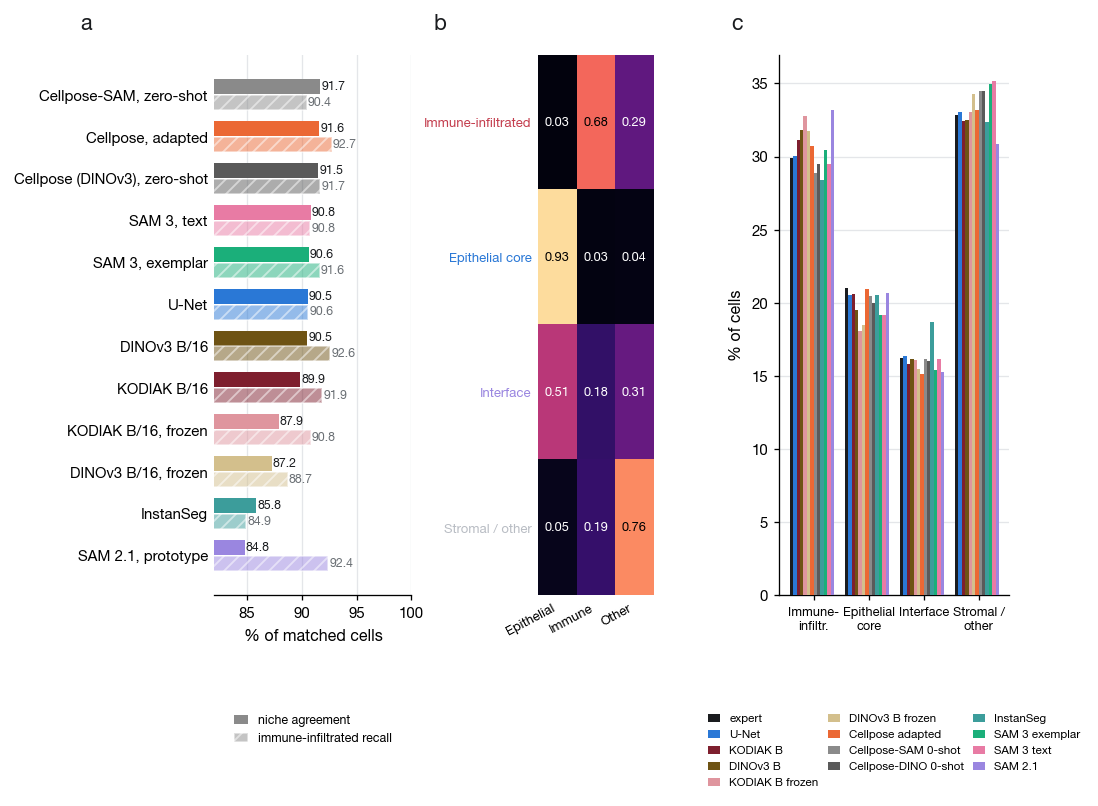

In [3]:
order = list(summ.sort_values("niche_agreement", ascending=False).index)
y = np.arange(len(order))[::-1]
fig = plt.figure(figsize=(7.6, 0.6 + 0.3 * max(len(order), 4) + 1.0))
gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 0.7, 1.4], wspace=0.7)
a = fig.add_subplot(gs[1])                                                     # b - the niche signatures
a.imshow(centers.values, cmap="magma", vmin=0, vmax=1, aspect="auto")
a.set_xticks(range(3), CLASSES, fontsize=7, rotation=28, ha="right"); a.set_yticks(range(4), centers.index, fontsize=7)
for t, n in zip(a.get_yticklabels(), centers.index):
    t.set_color(NICHE_COLOR[n]); t.set_fontweight("bold")
for i in range(4):
    for j in range(3):
        a.text(j, i, f"{centers.values[i, j]:.2f}", ha="center", va="center", fontsize=6.8, color="white" if centers.values[i, j] < 0.55 else "black")
for s_ in a.spines.values():
    s_.set_visible(False)
a.tick_params(length=0)
panel(a, "b", dx=-0.8)
b = fig.add_subplot(gs[0])                                                     # a - recovery
b.barh(y + 0.19, summ.loc[order, "niche_agreement"], 0.36, color=[MCOLOR[m] for m in order], zorder=3, label="niche agreement")
b.barh(y - 0.19, summ.loc[order, "immune_recall"], 0.36, color=[MCOLOR[m] for m in order], alpha=0.5, hatch="///", edgecolor="white", zorder=3, label="immune-infiltrated recall")
for i, m in enumerate(order):
    b.text(summ.loc[m, "niche_agreement"] + 0.1, y[i] + 0.19, f"{summ.loc[m, 'niche_agreement']:.1f}", va="center", fontsize=6.6, color=INK)
    b.text(summ.loc[m, "immune_recall"] + 0.1, y[i] - 0.19, f"{summ.loc[m, 'immune_recall']:.1f}", va="center", fontsize=6.6, color=MUTED)
lo = np.floor(np.nanmin(summ[["niche_agreement", "immune_recall"]].values) - 2)
b.set_yticks(y, [LABEL[m] for m in order]); b.set_xlim(lo, 100); b.set_xlabel("% of matched cells")
b.legend(fontsize=6.6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, handlelength=1.2)
xgrid(b); barh_clean(b)
panel(b, "a", dx=-0.62)
c = fig.add_subplot(gs[2])                                                     # c - abundance
nn = list(NICHE_COLOR)
xx = np.arange(len(nn))
w = 0.8 / (len(METHODS) + 1)
c.bar(xx, [100 * (expert.niche == n).mean() for n in nn], w, color=INK, zorder=3, label="expert")
for i, m in enumerate(METHODS):
    c.bar(xx + (i + 1) * w, [100 * (niche_cells[m].niche == n).mean() for n in nn], w, color=MCOLOR[m], zorder=3, label=SHORT[m])
c.set_xticks(xx + 0.4, ["Immune-\ninfiltr.", "Epithelial\ncore", "Interface", "Stromal /\nother"], fontsize=6.8)
c.set_ylabel("% of cells")
c.legend(fontsize=6.2, ncol=3, handlelength=1.0, columnspacing=0.8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ygrid(c)
panel(c, "c", dx=-0.16)
plt.show()

**Figure 1 — Reference niches and their recovery.** (a) Per-cell niche agreement of each method's cells, assigned
through their own graphs and phenotypes, and recall of the immune-infiltrated niche — the clinically meaningful one.
(b) The four cellular neighborhoods discovered on the expert cells, as mean window composition — the definition of
every color below. (c) Niche abundance under every method against the expert reference; the abundances agree within a
few percentage points because niche assignment has basins: a window has to change composition substantially before
its cluster changes.

## 2. The ecosystem maps

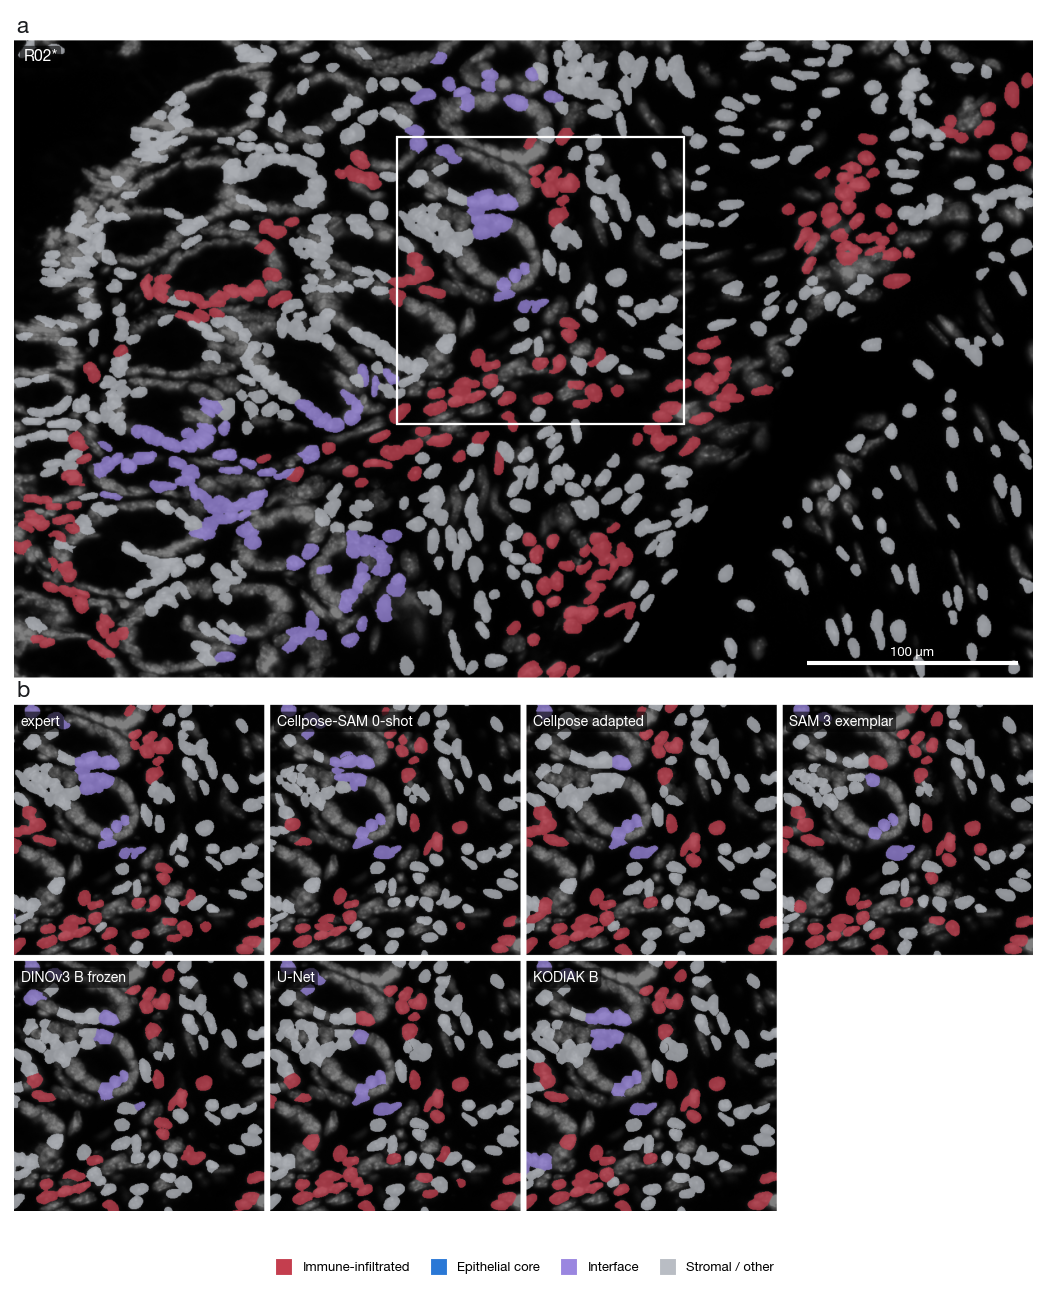

In [4]:
import cv2

def niche_map(key, labels, table, id_col):
    base = np.repeat((norm01(TEST[key]["dapi"]) * 0.5)[..., None], 3, -1)
    lut = np.zeros((int(labels.max()) + 1, 3)); has = np.zeros(int(labels.max()) + 1, bool)
    sub = table[table.region == key]
    for cid, niche in zip(sub[id_col].astype(int), sub.niche):
        if 0 < cid < len(lut):
            lut[cid], has[cid] = hex2rgb(NICHE_COLOR[niche]), True
    mk = has[labels]
    base[mk] = 0.25 * base[mk] + 0.75 * lut[labels[mk]]
    return base

key = f"{TEST_SLIDE}_R02"
gtl = TEST[key]["labels"]
Z, ZS, GAP = (140, 560), 420, 10                                               # zoom origin (y, x), zoom size, mosaic gap
ref = niche_map(key, gtl, expert, "id")
zooms = [("expert", ref)] + [(SHORT[m], niche_map(key, pred_of(m, key), niche_cells[m], "pred_id")) for m in SHOW]
zooms = [(t, img[Z[0]:Z[0] + ZS, Z[1]:Z[1] + ZS]) for t, img in zooms][:8]
NCOL = 4
CW = NCOL * ZS + (NCOL - 1) * GAP
f = CW / ref.shape[1]
ref_s = cv2.resize(ref, (CW, int(ref.shape[0] * f)), interpolation=cv2.INTER_AREA)
BAND = 46
nrow = int(np.ceil(len(zooms) / NCOL))
rows = [np.ones((BAND, CW, 3)), ref_s, np.ones((BAND, CW, 3))]
for r in range(nrow):
    row = np.ones((ZS, CW, 3))
    for k in range(NCOL):
        idx = NCOL * r + k
        if idx < len(zooms):
            row[:, k * (ZS + GAP):k * (ZS + GAP) + ZS] = zooms[idx][1]
    rows.append(row)
    if r < nrow - 1:
        rows.append(np.ones((GAP, CW, 3)))
canvas = np.vstack(rows)
fig, ax = plt.subplots(figsize=(7.6, 7.6 * canvas.shape[0] / CW + 0.3))
fig.subplots_adjust(left=0, right=1, top=1, bottom=0.04)
ax.imshow(canvas); ax.set_axis_off()
ax.text(4, BAND - 14, "a", fontsize=12, fontweight="bold", color=INK)
ax.text(4, BAND + ref_s.shape[0] + BAND - 14, "b", fontsize=12, fontweight="bold", color=INK)
ax.text(16, BAND + 34, tag(key), fontsize=8.5, fontweight="bold", color="white", bbox=CHIP)
ax.add_patch(plt.Rectangle((Z[1] * f, BAND + Z[0] * f), ZS * f, ZS * f, fill=False, ec="white", lw=1.2))
L = 100 / PX_UM * f
ax.plot([CW - 24 - L, CW - 24], [BAND + ref_s.shape[0] - 26] * 2, color="white", lw=2.2, solid_capstyle="butt")
ax.text(CW - 24 - L / 2, BAND + ref_s.shape[0] - 38, "100 µm", color="white", ha="center", fontsize=7)
y0 = BAND + ref_s.shape[0] + BAND
for idx, (t, _) in enumerate(zooms):
    r, k = divmod(idx, NCOL)
    ax.text(k * (ZS + GAP) + 12, y0 + r * (ZS + GAP) + 34, t, fontsize=7.5, fontweight="bold", color="white", bbox=CHIP)
handles = [plt.Line2D([], [], marker="s", ls="", ms=7, color=v, label=k) for k, v in NICHE_COLOR.items()]
fig.legend(handles=handles, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.02), fontsize=7, handletextpad=0.4, columnspacing=1.2)
plt.show()

**Figure 2 — The ecosystem maps.** (a) The dense region R02 with every expert cell filled by its reference niche over
dim DAPI, where immune infiltration threads between tumor nests (bar 100 µm; white box = the zoom). (b) The zoom for
the expert reference and each method, cells assigned through the method's own boundaries, phenotypes and graph; only
matched cells are painted, so dark gaps are unmatched or spurious cells.

## 3. Propagation across the four levels (§5.5)

The central analysis links the levels rather than treating them as independent benchmarks: is technical segmentation
accuracy a sufficient predictor of downstream biological reliability?

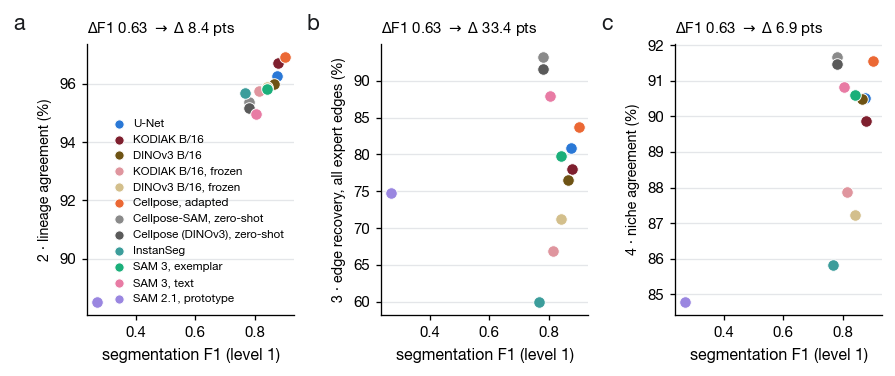

                                F1  2 · lineage agreement (%)  3 · edge recovery, all expert edges (%)  4 · niche agreement (%)
method                                                                                                                         
U-Net                         0.87                      96.26                                    80.83                    90.52
KODIAK B/16                   0.88                      96.71                                    78.01                    89.86
DINOv3 B/16                   0.86                      95.97                                    76.53                    90.48
KODIAK B/16, frozen           0.81                      95.76                                    66.93                    87.88
DINOv3 B/16, frozen           0.84                      95.87                                    71.28                    87.23
Cellpose, adapted             0.90                      96.93                                    83.73  

In [5]:
bench = pd.read_csv(ANALYSIS / "benchmark_region.csv", index_col=0)
ph = pd.read_csv(ANALYSIS / "phenotype_summary.csv", index_col=0)
nb = pd.read_csv(ANALYSIS / "neighborhood_summary.csv", index_col=0)
LEVELS = {"2 · lineage agreement (%)": ph.lineage_agreement, "3 · edge recovery, all expert edges (%)": 100 * nb.edge_recall_all,
          "4 · niche agreement (%)": summ.niche_agreement}
lv = pd.DataFrame({"F1": bench["f1@0.5"], **LEVELS}).reindex(METHODS).dropna()
fig, axes = plt.subplots(1, 3, figsize=(7.6, 2.6))
fig.subplots_adjust(wspace=0.42)
for a, (name, _) in zip(axes, LEVELS.items()):
    for m in lv.index:
        a.scatter(lv.loc[m, "F1"], lv.loc[m, name], color=MCOLOR[m], s=38, zorder=3, edgecolor="white", lw=0.5, label=LABEL[m])
    a.set_xlabel("segmentation F1 (level 1)"); a.set_ylabel(name, fontsize=7.6)
    dx, dy = lv.F1.max() - lv.F1.min(), lv[name].max() - lv[name].min()
    a.set_title(f"ΔF1 {dx:.2f} $\\rightarrow$ Δ {dy:.1f} pts", fontsize=8)
    ygrid(a)
for a, letter in zip(axes, "abc"):
    panel(a, letter, dx=-0.3)
axes[0].legend(fontsize=6.2, loc="lower right", handletextpad=0.2, markerscale=0.8)
plt.show()
print(lv.round(2).rename(index=LABEL).to_string())

**Figure 3 — Conventional segmentation metrics overstate downstream differences.** Each panel plots one downstream
level against segmentation F1, one dot per method; the title gives the spread across methods at both ends. A large
spread in F1 collapses to a few percentage points of lineage agreement and niche agreement. Three mechanisms buffer
the propagation: spatial autocorrelation (most misassigned pixels share the affected cell's lineage), aggregation
(neighborhood windows average over 6–10 cells) and the basin structure of niche assignment. Edge recovery against all
expert edges is the level that keeps tracking F1, because it charges missed cells for their lost relationships — the
channel through which segmentation still matters, together with heterotypic merges and multi-marker states.

One slide, four scored regions: this demonstrates the framework; population claims need more slides.

---
**References.** Schürch et al., *Coordinated Cellular Neighborhoods Orchestrate Antitumoral Immunity at the
Colorectal Cancer Invasive Front*, Cell 2020 — the CN method. Keren et al., Cell 2018 — tumor-immune
architectures. Palla et al., Nature Methods 2022 — spatial graph conventions.